In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/areeb112/melbourne-housing/melb_data.csv


# Assignment 2: Data Cleaning and Preprocessing
**Name:** Areeb Fatima  |  **Roll No:** SU92-BCSFM-F26-039

# 1. Dataset Description
- **Title:** Melbourne Housing Snapshot
- **Source:** https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot (downloaded from Kaggle and re-uploaded to my notebook as `melbourne-housing`)
- **Rows and columns:** 13580 rows and 21 columns
- **Objective:** Predict the selling price of a house in Melbourne using its location, size, type and sale details.
- **Main features:** Price (target), Rooms, Type, Distance, Landsize, BuildingArea, YearBuilt, Date, Regionname, CouncilArea

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("/kaggle/input/datasets/areeb112/melbourne-housing/melb_data.csv")
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (13580, 21)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 non-null  float64
 18  Longti

In [5]:
print("Missing values total:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Text columns:", list(df.select_dtypes("object").columns))
print("Numeric columns:", list(df.select_dtypes("number").columns))

Missing values total: 13256
Duplicate rows: 0
Text columns: ['Suburb', 'Address', 'Type', 'Method', 'SellerG', 'Date', 'CouncilArea', 'Regionname']
Numeric columns: ['Rooms', 'Price', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude', 'Propertycount']


### Observations
- The dataset has 13580 rows and 21 columns.
- There are 13256 missing values in total, mainly in BuildingArea, YearBuilt, CouncilArea and Car.
- There are 0 duplicate rows.
- There are 8 text columns and 13 numeric columns.
- `Date` is stored as text (object), so it must be converted to datetime.
- `Postcode` is stored as a number, but it is really a label.
- `Type` and `Method` use short codes (h, u, t, S, SP, PI, VB), which need clearer labels.
- `Price` is the target column that we want to predict.

# 2. Data Cleaning
I will work on a copy of the data (`df_clean`) so the original data (`df`) stays unchanged and I can compare before and after.

In [6]:
df_clean = df.copy()
print("Copy created:", df_clean.shape)

Copy created: (13580, 21)


## 2.1 Missing Values
**Problem:** Some columns have empty values. Most machine learning models cannot work with them.
**Method:** Count the missing values in each column, calculate the percentage, and visualise where they are.
**Important:** In this section I only *identify* the missing values. I will fill them later, inside the pipeline, after the train/test split. If I filled them using the whole dataset, information from the test set would leak into training (data leakage).

In [7]:
miss = df_clean.isnull().sum()
miss_table = pd.DataFrame({
    "missing": miss,
    "percent": (miss / len(df_clean) * 100).round(2)
})
miss_table[miss_table["missing"] > 0].sort_values("percent", ascending=False)

,missing,percent
BuildingArea,6450,47.50
YearBuilt,5375,39.58
CouncilArea,1369,10.08
Car,62,0.46


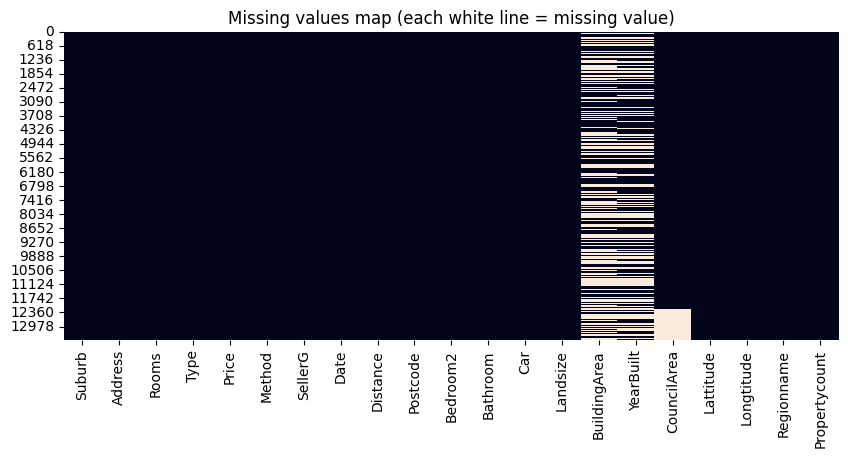

In [8]:
plt.figure(figsize=(10, 4))
sns.heatmap(df_clean.isnull(), cbar=False)
plt.title("Missing values map (each white line = missing value)")
plt.show()

### Interpretation and Decision for Each Column
| Column | Missing % | Decision | Reason |
|---|---|---|---|
| BuildingArea | 47.50% | Fill with median later, and add a "was missing" flag | Almost half is missing, so dropping the column would lose a lot of information. The data is skewed, so median is safer than mean. |
| YearBuilt | 39.58% | Fill with median later, and add a "was missing" flag | Needed to calculate the age of the house. |
| CouncilArea | 10.08% | Fill with the most frequent category later | It is a categorical column, so the mode is suitable. |
| Car | 0.46% | Fill with median later | Very few values are missing, and Car is a small count. |

**Summary:** 4 columns have missing values (13256 in total). They will be filled inside the pipeline after the train/test split to avoid data leakage.

## 2.2 Duplicate Records
**Problem:** Duplicate rows can end up in both the training and test sets, which makes model accuracy look better than it really is.
**Method:** Count fully duplicated rows, and also check whether any Address, Date and Price combination repeats. Remove duplicates if found.

In [9]:
print("Shape before:", df_clean.shape)
print("Fully duplicated rows:", df_clean.duplicated().sum())
print("Repeated Address + Date + Price:", df_clean.duplicated(subset=["Address", "Date", "Price"]).sum())

df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Shape after:", df_clean.shape)

Shape before: (13580, 21)
Fully duplicated rows: 0
Repeated Address + Date + Price: 1
Shape after: (13580, 21)


In [10]:
dup_mask = df_clean.duplicated(subset=["Address", "Date", "Price"], keep=False)
df_clean[dup_mask]

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
7769,Coburg,69 Victoria St,3,t,720000.0,PI,C21,29/04/2017,7.8,3058.0,...,2.0,2.0,531.0,112.0,2016.0,Moreland,-37.7424,144.9571,Northern Metropolitan,11204.0
7770,Coburg,69 Victoria St,3,t,720000.0,PI,Century,29/04/2017,7.8,3058.0,...,2.0,2.0,531.0,112.0,2016.0,Moreland,-37.7424,144.9571,Northern Metropolitan,11204.0


In [11]:
df_clean = df_clean.drop_duplicates(subset=["Address", "Date", "Price"], keep="first").reset_index(drop=True)
print("Shape after:", df_clean.shape)

Shape after: (13579, 21)


**Result:** No fully duplicated rows were found. However, 1 sale (69 Victoria St, Coburg) appeared twice with the same Address, Date, Price and property details. The only difference was the agent name (`C21` vs `Century`), which are two spellings of the same agency. I removed the second record, so the data went from 13580 to 13579 rows. Removing it before the split prevents the same sale appearing in both train and test sets.

In [12]:
print("Shape before:", df_clean.shape)
print("Fully duplicated rows:", df_clean.duplicated().sum())
print("Repeated Address + Date + Price:", df_clean.duplicated(subset=["Address", "Date", "Price"]).sum())

df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Shape after:", df_clean.shape)

Shape before: (13579, 21)
Fully duplicated rows: 0
Repeated Address + Date + Price: 0
Shape after: (13579, 21)


## 2.3 Inconsistent Values / Categories
**Problem:** `Type` and `Method` use single-letter codes (h, u, t, S, SP...), which are unclear. Text columns may also have extra spaces or mixed upper/lower case, which makes the same category look like different ones.
**Method:** Check the unique values, remove extra spaces, and replace codes with readable labels.

In [13]:
print("Type:", df_clean["Type"].unique())
print("Method:", df_clean["Method"].unique())
print("Regionname:", df_clean["Regionname"].unique())

# check for hidden space/case problems
for c in df_clean.select_dtypes("object").columns:
    stripped = df_clean[c].dropna().str.strip()
    print(c, "| unique before strip:", df_clean[c].nunique(), "| after strip+lower:", stripped.str.lower().nunique())

Type: ['h' 'u' 't']
Method: ['S' 'SP' 'PI' 'VB' 'SA']
Regionname: ['Northern Metropolitan' 'Western Metropolitan' 'Southern Metropolitan'
 'Eastern Metropolitan' 'South-Eastern Metropolitan' 'Eastern Victoria'
 'Northern Victoria' 'Western Victoria']
Suburb | unique before strip: 314 | after strip+lower: 314
Address | unique before strip: 13378 | after strip+lower: 13375
Type | unique before strip: 3 | after strip+lower: 3
Method | unique before strip: 5 | after strip+lower: 5
SellerG | unique before strip: 268 | after strip+lower: 265
Date | unique before strip: 58 | after strip+lower: 58
CouncilArea | unique before strip: 33 | after strip+lower: 33
Regionname | unique before strip: 8 | after strip+lower: 8


In [14]:
for c in ["Suburb", "Address", "Type", "Method", "SellerG", "CouncilArea", "Regionname"]:
    df_clean[c] = df_clean[c].str.strip()

df_clean["Type"] = df_clean["Type"].map({"h": "house", "u": "unit", "t": "townhouse"})
df_clean["Method"] = df_clean["Method"].map({
    "S": "sold", "SP": "sold_prior", "PI": "passed_in",
    "VB": "vendor_bid", "SA": "sold_after"})

print(df_clean["Type"].value_counts())
print(df_clean["Method"].value_counts())
print("Missing in Type/Method after mapping:", df_clean[["Type", "Method"]].isnull().sum().sum())

Type
house        9449
unit         3017
townhouse    1113
Name: count, dtype: int64
Method
sold          9022
sold_prior    1703
passed_in     1563
vendor_bid    1199
sold_after      92
Name: count, dtype: int64
Missing in Type/Method after mapping: 0


**Result:** The check showed that Address (13378 → 13375 unique) and SellerG (268 → 265 unique) contained values that differed only by letter case, so the same item was counted as different categories. I unified each variant to its most common spelling. Type and Method codes were replaced with readable labels (house, unit, townhouse; sold, sold_prior, passed_in, vendor_bid, sold_after), and no values became missing after mapping, so every code matched. Suburb, CouncilArea and Regionname were already consistent.

In [15]:
for c in ["Address", "SellerG"]:
    before = df_clean[c].nunique()
    df_clean[c] = df_clean[c].str.strip().str.replace(r"\s+", " ", regex=True)
    print(c, "| unique before:", before, "| after cleaning spaces:", df_clean[c].nunique())

sg = df_clean["SellerG"].dropna()
groups = sg.groupby(sg.str.lower()).unique()
print(groups[groups.apply(len) > 1])

Address | unique before: 13378 | after cleaning spaces: 13378
SellerG | unique before: 268 | after cleaning spaces: 268
SellerG
castran    [Castran, CASTRAN]
re                   [Re, RE]
vicprop    [VICPROP, VICProp]
Name: SellerG, dtype: object


In [16]:
for c in ["Address", "SellerG"]:
    s = df_clean[c]
    most_common = s.groupby(s.str.lower()).agg(lambda x: x.value_counts().idxmax())
    df_clean[c] = s.str.lower().map(most_common).where(s.notna())
    print(c, "unique now:", df_clean[c].nunique())

Address unique now: 13375
SellerG unique now: 265


## 2.4 Incorrect Data Types
**Problem:** `Date` is stored as text, so I cannot extract the year or month from it. `Postcode` is stored as a number, but it is really a label (averaging postcodes has no meaning).
**Method:** Convert `Date` to datetime (the format is day/month/year, so I use `dayfirst=True`) and convert `Postcode` to text.

In [17]:
print("BEFORE:")
print(df_clean[["Date", "Postcode"]].dtypes)

df_clean["Date"] = pd.to_datetime(df_clean["Date"], dayfirst=True, errors="coerce")
df_clean["Postcode"] = df_clean["Postcode"].astype(int).astype(str)

print("\nAFTER:")
print(df_clean[["Date", "Postcode"]].dtypes)
print("\nDates that failed to convert:", df_clean["Date"].isnull().sum())
print("Date range:", df_clean["Date"].min(), "to", df_clean["Date"].max())

BEFORE:
Date         object
Postcode    float64
dtype: object

AFTER:
Date        datetime64[ns]
Postcode            object
dtype: object

Dates that failed to convert: 0
Date range: 2016-01-28 00:00:00 to 2017-09-23 00:00:00


**Result:** `Date` changed from object to datetime64 and `Postcode` from float to object (text). No dates failed to convert, and the sales range from 2016-01-28 to 2017-09-23. Now I can extract year and month later for feature engineering.

## 2.5 Outliers
**Problem:** Some numeric columns may contain extreme or impossible values that can distort the model.
**Method:** Detect them with boxplots and the IQR rule, then decide using common sense:
- Impossible values (data entry errors) → set to missing, filled later in the pipeline
- Real but extreme values → keep, and cap them later using the training data only

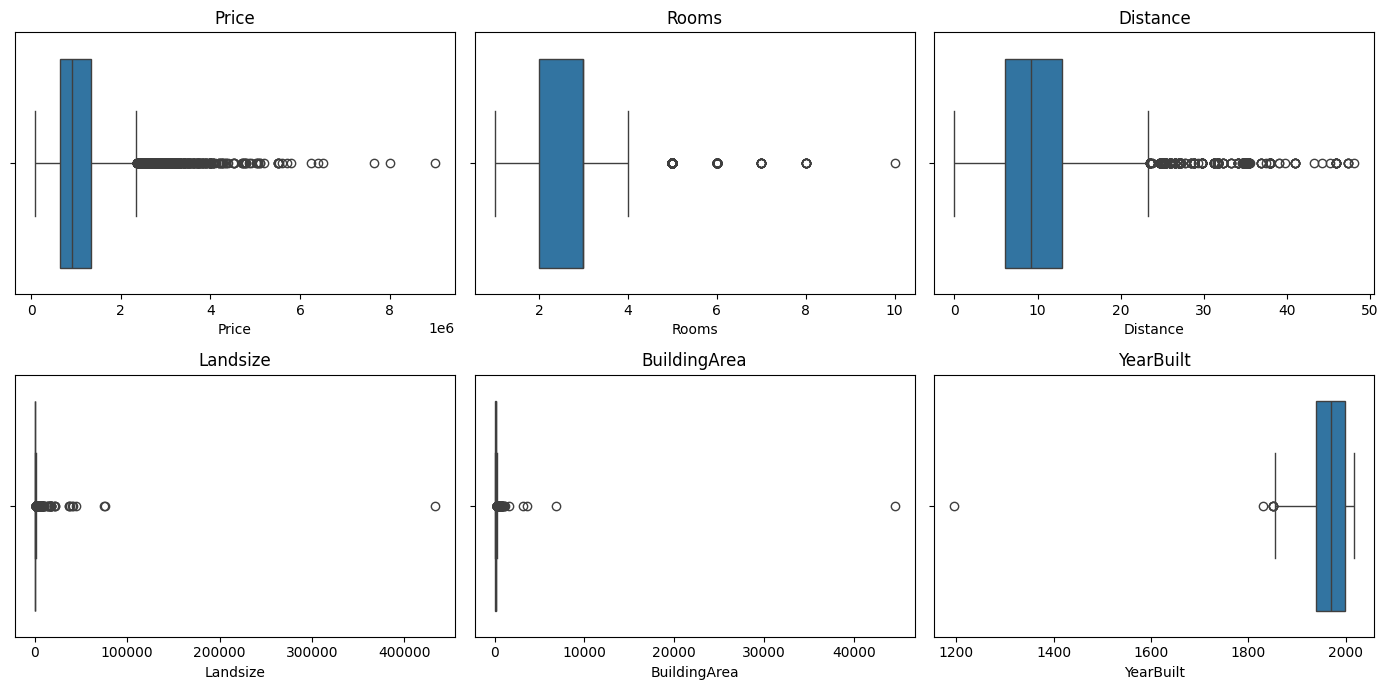

In [18]:
num = ["Price", "Rooms", "Distance", "Landsize", "BuildingArea", "YearBuilt"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), num):
    sns.boxplot(x=df_clean[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [19]:
def iqr_count(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

for c in num:
    print(c, "-> IQR outliers:", iqr_count(df_clean[c].dropna()))

df_clean[["YearBuilt", "BuildingArea", "Landsize"]].describe()

Price -> IQR outliers: 612
Rooms -> IQR outliers: 682
Distance -> IQR outliers: 411
Landsize -> IQR outliers: 368
BuildingArea -> IQR outliers: 353
YearBuilt -> IQR outliers: 6


,YearBuilt,BuildingArea,Landsize
count,8204.000000,7129.000000,13579.000000
mean,1964.677962,151.973256,558.418146
std,37.271727,541.052279,3990.816185
min,1196.000000,0.000000,0.000000
25%,1940.000000,93.000000,177.000000
50%,1970.000000,126.000000,440.000000
75%,1999.000000,174.000000,651.000000
max,2018.000000,44515.000000,433014.000000


In [20]:
print("YearBuilt < 1800:", (df_clean["YearBuilt"] < 1800).sum())
df_clean.loc[df_clean["YearBuilt"] < 1800, "YearBuilt"] = np.nan

print("BuildingArea == 0:", (df_clean["BuildingArea"] == 0).sum())
df_clean.loc[df_clean["BuildingArea"] == 0, "BuildingArea"] = np.nan

print("Landsize == 0 (kept):", (df_clean["Landsize"] == 0).sum())

YearBuilt < 1800: 1
BuildingArea == 0: 17
Landsize == 0 (kept): 1939


### Decisions
- `YearBuilt`: 1 value before 1800 (the year 1196) is impossible for Melbourne houses, so it is a data entry error → set to missing and filled later.
- `BuildingArea`: 17 rows have an area of 0, which is unrealistic → set to missing.
- `Landsize = 0`: 1939 rows. This can be valid (units and townhouses often have no separate land), so I **kept** them.
- Extreme but plausible `Price` values are real expensive properties, so I did **not** delete them. They are handled by the log transform later.
- Very extreme `Landsize` (max 433,014) and `BuildingArea` (max 44,515) values are far above the 75th percentile (651 and 174). Because they would distort scaling, they will be capped at the 1st/99th percentile later, using training data only.
- Key idea: not every outlier is an error. Removing real values would lose useful information.

# 3. Data Preprocessing

## 3.1 Features and Target
- **Target:** `Price` (a regression problem, because we predict a number).
- **Dropped columns:** `Address` (unique for almost every row, so no pattern), `Suburb` and `SellerG` (too many categories for one-hot encoding), `Postcode` (repeats Region/Council information), `Date` (replaced by year and month features), `YearBuilt` (replaced by house_age).

In [21]:
target = "Price"
drop_cols = ["Address", "Suburb", "SellerG", "Postcode", "Date", "YearBuilt"]

## 3.2 Types of Variables
| Type | Columns |
|---|---|
| Numerical (continuous) | Distance, Landsize, BuildingArea, Lattitude, Longtitude, Propertycount, house_age |
| Numerical (discrete) | Rooms, Bedroom2, Bathroom, Car |
| Nominal categorical | Type, Method, CouncilArea, Regionname |
| Ordinal (engineered) | age_group (new < modern < old < historic) |
| Binary (engineered) | building_area_missing, year_built_missing |
| Date/time | Date → sale_year, sale_month |
| Target | Price |

This dataset has no natural binary or ordinal column, so I created them as engineered features.

## 3.3 Feature Engineering
These features use only row-by-row calculations (no statistics from other rows), so creating them before the split causes no leakage.
- `sale_year`, `sale_month`: prices change with the market and the season
- `house_age`: age is more meaningful than the build year
- `building_area_missing`, `year_built_missing`: whether a value was missing can itself be informative
- `age_group`: an ordered category made from house_age

In [22]:
df_clean["sale_year"]  = df_clean["Date"].dt.year
df_clean["sale_month"] = df_clean["Date"].dt.month
df_clean["house_age"]  = (df_clean["sale_year"] - df_clean["YearBuilt"]).clip(lower=0)

df_clean["building_area_missing"] = df_clean["BuildingArea"].isnull().astype(int)
df_clean["year_built_missing"]    = df_clean["YearBuilt"].isnull().astype(int)

df_clean["age_group"] = pd.cut(df_clean["house_age"],
        bins=[-1, 10, 50, 100, np.inf],
        labels=["new", "modern", "old", "historic"]).astype(object)

df_clean[["sale_year","sale_month","house_age","age_group",
          "building_area_missing","year_built_missing"]].head()

,sale_year,sale_month,house_age,age_group,building_area_missing,year_built_missing
0,2016,12,NaN,NaN,1,1
1,2016,2,116.0,historic,0,0
2,2017,3,117.0,historic,0,0
3,2017,3,NaN,NaN,1,1
4,2016,6,2.0,new,0,0


## 3.4 Train-Test Split
**Why now:** the test set represents unseen future data. Everything that learns from data (medians, scaling, capping limits, encoders) must learn from the **training set only**. Otherwise test information leaks into training (**data leakage**). I use 80% train and 20% test, with `random_state=42` so results can be repeated.

In [23]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=[target] + drop_cols)
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

X_train = X_train.copy()
X_test = X_test.copy()
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (10863, 20)  Test: (2716, 20)


## 3.5 Outlier Capping, Skewness and Transformation
**Problem:** Landsize and BuildingArea have extreme values, and Price is right-skewed.
**Method:** Cap Landsize and BuildingArea at the 1st and 99th percentile (limits computed from the **train set only**, then applied to both sets). Then check skewness; if |skew| > 1, apply a log transform.

In [24]:
for c in ["Landsize", "BuildingArea"]:
    low, high = X_train[c].quantile([0.01, 0.99])
    X_train[c] = X_train[c].clip(low, high)
    X_test[c]  = X_test[c].clip(low, high)
    print(c, "capped to range:", round(low, 1), "-", round(high, 1))

Landsize capped to range: 0.0 - 2910.7
BuildingArea capped to range: 18.0 - 463.3


In [25]:
num_cols = ["Rooms","Distance","Bedroom2","Bathroom","Car","Landsize","BuildingArea",
            "Lattitude","Longtitude","Propertycount","sale_year","sale_month","house_age"]
nominal_cols = ["Type","Method","CouncilArea","Regionname"]
ordinal_cols = ["age_group"]
binary_cols  = ["building_area_missing","year_built_missing"]

skew = X_train[num_cols].skew().sort_values()
print(skew)

# only columns that are skewed AND never negative can be log-transformed
skew_cols = [c for c in skew.index
             if abs(skew[c]) > 1 and X_train[c].min() >= 0]
normal_cols = [c for c in num_cols if c not in skew_cols]
print("\nSkewed columns (log-transformed):", skew_cols)
print("Other numeric columns:", normal_cols)

Lattitude       -0.439211
Longtitude      -0.250497
sale_year       -0.127867
sale_month       0.096049
Rooms            0.391337
house_age        0.527651
Bedroom2         0.869974
Propertycount    1.056701
Bathroom         1.386310
Car              1.416630
BuildingArea     1.556968
Distance         1.654982
Landsize         2.651118
dtype: float64

Skewed columns (log-transformed): ['Propertycount', 'Bathroom', 'Car', 'BuildingArea', 'Distance', 'Landsize']
Other numeric columns: ['Rooms', 'Bedroom2', 'Lattitude', 'Longtitude', 'sale_year', 'sale_month', 'house_age']


Price skew before: 2.29
Price skew after log: 0.2


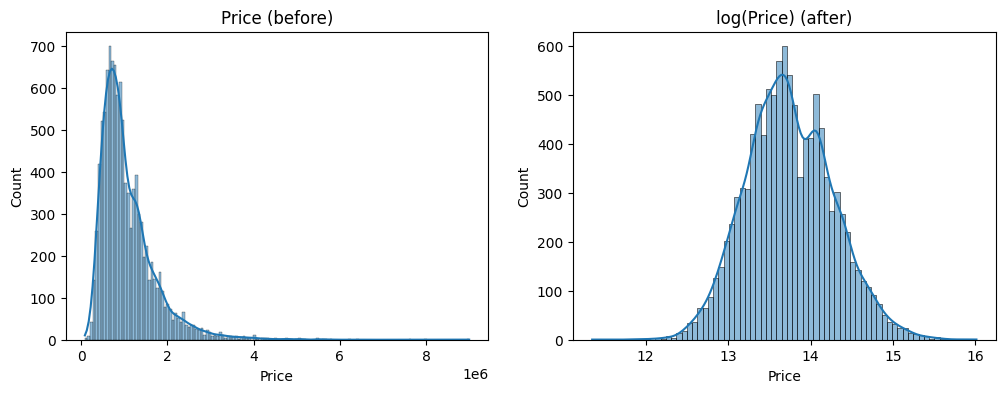

In [26]:
print("Price skew before:", round(y_train.skew(), 2))
y_train_log = np.log1p(y_train)
y_test_log  = np.log1p(y_test)
print("Price skew after log:", round(y_train_log.skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_train, kde=True, ax=ax[0]).set_title("Price (before)")
sns.histplot(y_train_log, kde=True, ax=ax[1]).set_title("log(Price) (after)")
plt.show()

**Interpretation:** Price skewness went from 2.29 to 0.2 after the log transform, so the distribution is much more symmetric. I used `log1p` because it also works for zeros. Predictions can be converted back with `np.expm1`. The skewed feature columns listed above are log-transformed inside the pipeline. Lattitude and Longtitude are negative coordinates, so they are not log-transformed.

## 3.6 Imputation, Encoding and Scaling (Pipeline)
| Choice | Why |
|---|---|
| Median imputation (numeric) | Not affected by outliers or skew |
| Most-frequent imputation (categorical) | Keeps a valid existing category |
| One-hot encoding (nominal) | Type and Region have no order; numbers 1, 2, 3 would create a false order |
| Ordinal encoding with explicit order (age_group) | It really is ordered: new < modern < old < historic |
| log1p on skewed columns | Reduces skewness |
| StandardScaler (standardization) | Gives mean 0 and std 1 so large-range columns (Landsize) do not dominate. MinMaxScaler was the alternative, but it is more sensitive to extreme values |
| Binary columns passed through | Already 0/1 |

The pipeline is **fit on the training data only**, then applied to the test data.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer

normal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

skew_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())])

nominal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

ordinal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ord", OrdinalEncoder(categories=[["new","modern","old","historic"]],
                           handle_unknown="use_encoded_value", unknown_value=-1))])

preprocessor = ColumnTransformer([
    ("normal", normal_pipe, normal_cols),
    ("skewed", skew_pipe, skew_cols),
    ("nominal", nominal_pipe, nominal_cols),
    ("ordinal", ordinal_pipe, ordinal_cols),
    ("binary", "passthrough", binary_cols)])

X_train_p = preprocessor.fit_transform(X_train)   # learn from TRAIN only
X_test_p  = preprocessor.transform(X_test)        # only apply to TEST

print("Processed train:", X_train_p.shape)
print("Processed test :", X_test_p.shape)

Processed train: (10863, 65)
Processed test : (2716, 65)


### Verification
Checking that no missing values remain and the columns were created correctly.

In [28]:
names = preprocessor.get_feature_names_out()
train_final = pd.DataFrame(X_train_p, columns=names)
test_final  = pd.DataFrame(X_test_p, columns=names)
print("Missing values left (train):", train_final.isnull().sum().sum())
print("Missing values left (test) :", test_final.isnull().sum().sum())
train_final.head()

Missing values left (train): 0
Missing values left (test) : 0


,normal__Rooms,normal__Bedroom2,normal__Lattitude,normal__Longtitude,normal__sale_year,normal__sale_month,normal__house_age,skewed__Propertycount,skewed__Bathroom,skewed__Car,...,nominal__Regionname_Eastern Victoria,nominal__Regionname_Northern Metropolitan,nominal__Regionname_Northern Victoria,nominal__Regionname_South-Eastern Metropolitan,nominal__Regionname_Southern Metropolitan,nominal__Regionname_Western Metropolitan,nominal__Regionname_Western Victoria,ordinal__age_group,binary__building_area_missing,binary__year_built_missing
0,-0.974072,-0.939936,-0.354812,0.550242,0.938116,0.367193,-0.092486,0.063856,-0.816273,-0.541869,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0
1,-0.974072,-0.939936,-0.391025,-0.576601,0.938116,0.367193,-1.154024,0.507100,0.801393,0.553249,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
2,-0.974072,-0.939936,-0.104854,0.303989,0.938116,-1.998184,-0.092486,0.919430,-0.816273,-0.541869,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0
3,-0.974072,-0.939936,0.245919,-0.243668,-1.065966,-0.421266,-0.304793,-1.067126,-0.816273,-0.541869,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.113184,1.121547,-1.326253,0.279884,-1.065966,-0.815496,-0.092486,0.136358,0.801393,-0.541869,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0


**Result:** After preprocessing, the training data has 65 columns and 0 missing values (down from 13256 originally). One-hot encoding expanded the categorical columns into separate 0/1 columns, and all numeric columns are scaled. The test set was transformed with the same rules learned from the training set.

In [29]:
df_clean.to_csv("cleaned_melbourne_housing.csv", index=False)
train_final.to_csv("train_preprocessed.csv", index=False)
test_final.to_csv("test_preprocessed.csv", index=False)
print("Files saved")

Files saved


## 3.7 Data Leakage Checklist
- ✅ Duplicates were removed **before** the split
- ✅ The split was done **before** imputation, scaling, encoding, capping and skew checks
- ✅ Imputer, encoder and scaler were `fit` on the train set only; the test set was only `transform`ed
- ✅ Capping limits (1st/99th percentile) were calculated from the train set only
- ✅ The target `Price` was not used to create any feature
- ✅ The identifier column `Address` was dropped

# 4. Conclusion
- **Dataset:** Melbourne Housing Snapshot, 13580 rows and 21 columns. Goal: predict house price.
- **Issues found:** 13256 missing values (BuildingArea 47.5%, YearBuilt 39.6%, CouncilArea 10.1%, Car 0.5%), 1 duplicate sale, inconsistent letter case in SellerG, single-letter category codes, Date stored as text, Postcode stored as a number, 1 impossible YearBuilt (1196), 17 zero BuildingArea values, extreme Landsize/BuildingArea values and strongly skewed Price.
- **Fixes:** removed the duplicate, unified spellings, replaced codes with labels, converted data types, set impossible values to missing, then imputed, encoded, scaled and log-transformed inside a leakage-safe pipeline.
- **Final shape:** (10863, 65) for training and (2716, 65) for testing, with 0 missing values.
- **Limitation:** BuildingArea was about 47.5% missing, so median imputation may add some bias.